In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import numpy.linalg as LA

## Generazione dei dati per la Regressione (vedi Lab 1)


In [ ]:
def datagen(d, points, m, M, w, sigma):

    # Inizializzo la matrice delle feature con zeri
    X = np.zeros((points,d))

    # Riempio ogni riga con un campione uniforme in [m, M]^d
    for i in range(points):
        X[i,:] = np.random.uniform(m, M, d)

        # Aggiungo un rumore gaussiano a ogni target
    eps = np.random.normal(0, sigma, points)

    # Calcolo i target come combinazione lineare delle feature + rumore
    y = np.dot(X,w) + eps
    return X, y

In [ ]:
# Fisso la dimensionalità delle feature
d = 50

# Genero i pesi del modello di una matrice standard
w = np.random.normal(0, 1, d)

# Fisso la deviazione standard del rumore
sigma = 0.1

# Fisso iò numero di punti nel traiding test e nel set test
points = 100
points_test = 100

# Fisso gli estremi dell'intervallo uniforme da cui campionare le feature
m = -10
M = 10

# Genero il dataset di training (X, y)
X, y = datagen(d, points, m, M, w, sigma)

---

In [ ]:
# Grazie a Claude per la bella animazione della discesa del gradiente!

# Importo la classe per creare animazioni e HTML per mostrarle nel notebook
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
plt.rcParams["animation.frame_format"] = "jpeg"

# Genero un dataset 2D "giocattolo" per visualizzare la discesa del gradiente
X_toy, y_toy = datagen(2, 200, -10, 10, np.array([1.5, -2.0]), 1.0)

# Rendo la seconda feature "più debole" (scalo di 0.3) per creare una valle stretta
X_toy[:, 1] *= 0.3
n = len(y_toy)

# Definisco la loss (MSE) e il suo gradiente come funzioni lambda
loss   = lambda w: np.mean((y_toy - X_toy @ w) ** 2)
grad   = lambda w: -(2 / n) * X_toy.T @ (y_toy - X_toy @ w)

# Calcolo la soluzione in forma chiusa (ottimo) della regressione
w_star = np.linalg.solve(X_toy.T @ X_toy, X_toy.T @ y_toy)

# Calcolo il massimo autovalore di (2/n) X^T X, utile per la stabilità del learning rate
lam_max = np.linalg.eigvalsh(2 / n * X_toy.T @ X_toy).max()


def animate_gd(gamma0, iters=40, w0=(1.1, -5.0), schedule=None):
    """schedule(t, gamma0) -> gamma_t  (None = lr costante)"""
    # Inizializzo il punto di partenza e salvo la loss iniziale
    w = np.array(w0, float)
    path, losses = [w.copy()], [loss(w)]

    # Itero l'aggiornamento GD, applicando eventualmente lo schedule sul learning rate
    for t in range(iters):
        gamma0 = gamma0 if schedule is None else schedule(t, gamma0)
        w = w - gamma0 * grad(w)
        path.append(w.copy()); losses.append(loss(w))
    path, losses = np.array(path), np.array(losses)

    # Preparo lo sfondo con le curve di livello della loss intorno all'ottimo
    g1 = np.linspace(w_star[0] - 0.6, w_star[0] + 0.6, 150)
    g2 = np.linspace(w_star[1] - 2.2, w_star[1] + 2.2, 150)
    Z = np.array([[loss(np.array([a, b])) for a in g1] for b in g2])

    # Creo la figura con due pannelli: a sinistra il percorso nello spazio dei pesi, a destra l'andamento della loss in scala logaritmica
    fig, (ax, axl) = plt.subplots(1, 2, figsize=(22, 9), dpi=90)
    ax.contour(g1, g2, Z, levels=np.geomspace(Z.min() + 1e-2, Z.max(), 18), cmap="viridis")
    ax.plot(*w_star, "r*", ms=15, label=r"$w^*$")
    ax.set_xlim(g1[0], g1[-1]); ax.set_ylim(g2[0], g2[-1])
    ax.set_xlabel(r"$w_1$"); ax.set_ylabel(r"$w_2$"); ax.legend(loc="upper right")

    # Preparo le linee vuote (trail = percorso, head = punto corrente)
    (trail,) = ax.plot([], [], "o-", c="tab:orange", ms=4, lw=1)
    (head,)  = ax.plot([], [], "o", c="red", ms=8)

    axl.set_xlim(0, iters); axl.set_yscale("log")
    axl.set_ylim(min(losses.min(), loss(w_star)) * 0.7, max(losses[0], 1) * 3)
    axl.set_xlabel("iterazione"); axl.set_ylabel("loss (MSE)"); axl.grid(alpha=0.3)
    (lcurve,) = axl.plot([], [], "o-", c="tab:orange", ms=4)

    # Funzione di aggiornamento richiamata da FuncAnimation a ogni frame
    def update(k):
        trail.set_data(path[:k + 1, 0], path[:k + 1, 1])
        head.set_data([path[k, 0]], [path[k, 1]])
        lcurve.set_data(np.arange(k + 1), losses[:k + 1])
        fig.suptitle(f"GD  |  step {k}  |  loss = {losses[k]:.3g}")

    # Creo l'animazione e restituisco l'HTML per il notebook
    anim = FuncAnimation(fig, update, frames=iters + 1, interval=200)
    plt.close(fig)
    return HTML(anim.to_jshtml())

In [ ]:
def my_schedule(t, gamma0):
    # Lascio il learning rate costante per tutta la durata dell'ottimizzazione
    return gamma0
    
# Lancio la GD con learning rate costante
animate_gd(gamma0=0.01, iters=100, schedule=my_schedule)

In [ ]:
def my_schedule(t, gamma0):
    # Ogni 10 step (dal secondo in poi) dimezzo il learning rate
    if t % 10 == 0 and t > 0:
        new_gamma = gamma0 * 0.5
        print(f"Step {t}: learning rate ridotto a {new_gamma:.4f}")
        return new_gamma
    else:
        return gamma0
    
# Lancio la GD con learning rate decrescente
animate_gd(gamma0=0.09, iters=100, schedule=my_schedule)

# Regressione Lineare e Logistica Regolarizzata

Attività per questo laboratorio:

* Generare dati linearmente separabili con diversi livelli di rumore;

* Calcolare la soluzione della Regressione ai Minimi Quadrati (LSR) senza o con regolarizzazione (Ridge, Lasso ed Elastic Net);

* Verificare quale dei tre metodi ottiene il miglior errore sul test set.

## Discesa del Gradiente per la Regressione Lineare (Regolarizzata)

Loss dell'errore quadratico e suo gradiente per la **regressione lineare non regolarizzata** (vedi Lab 2):


$$
\mathcal{L}=\frac{1}{n}\|y-Xw\|_{2}^{2},\;\;\;\;\nabla_{w} \mathcal{L} = -\frac{2}{n}X^T(y-Xw)
$$

In [ ]:
def SquareLoss(X, y, w):
    # Calcolo la loss dei minimi quadrati (MSE) come (1/n) * ||y - Xw||_2^2
    points = X.shape[0]
    return (1 / (points)) * LA.norm(y-X@w,2)**2


def OLSGradient(X, y, w, points):
    # Calcolo il gradiente della loss rispetto ai pesi: -(2/n) X^T (y - Xw)
    return (-2 / points) * (X.T @ (y - X @ w))


def GD(X, y, iters, gamma, d):
    # 1. Inizializzo le matrici che salveranno i pesi e la loss a ogni iterazione
    W = np.zeros((d,iters))
    L = np.zeros(iters)
    points = X.shape[0]

    # 2. Inizializzo i pesi con piccoli valori casuali (vicini a 0)
    w = np.random.normal(0, 0.1, d)

    # 3. A ogni iterazione salvo lo stato corrente e faccio un passo di GD
    for i in range(iters):
        W[:,i] = w
        L[i] = SquareLoss(X,y,w)
        w = w - gamma*OLSGradient(X, y, w, points)
    return W, L

In [ ]:
# Rigenero il dataset 50-dimensionale prima di eseguire la GD
X, y = datagen(d, points, m, M, w, sigma)

# Estraggo la dimensionalità delle feature dal dataset
d = np.shape(X)[1]

# Fissо numero di iterazioni e learning rate
iters = 100
gamma = 0.001 

# Eseguo la discesa del gradiente
wgd, L = GD(X, y, iters, gamma, d)

# Estraggo i pesi appresi all'ultima iterazione
wpred = wgd[:,-1]

# Confronto i pesi appresi con quelli reali usando la norma L2 della differenza
print('Norma L2 della differenza tra pesi reali e pesi predetti: ', LA.norm(w-wpred,2))
print(f"norma di w={np.linalg.norm(wpred):.4f}")

## Regressione Ridge

Qualche parola sulla regolarizzazione

Vi ricordate la soluzione in forma chiusa per la regressione lineare? Nel caso ve la foste dimenticata...

$$
y=Xw,\;\;\;\; w=X^{-1}y,\;\;\;\;X^{-1}=(X^{T}X)^{-1}X^{T}
$$

$$
w=(X^{T}X)^{-1}X^{T}y
$$

Questa è davvero bella...davvero...[ma](https://cdn3.emoji.gg/stickers/2066-nerd-doggo.png) potrebbe esserci un problema.
Questo problema è noto come

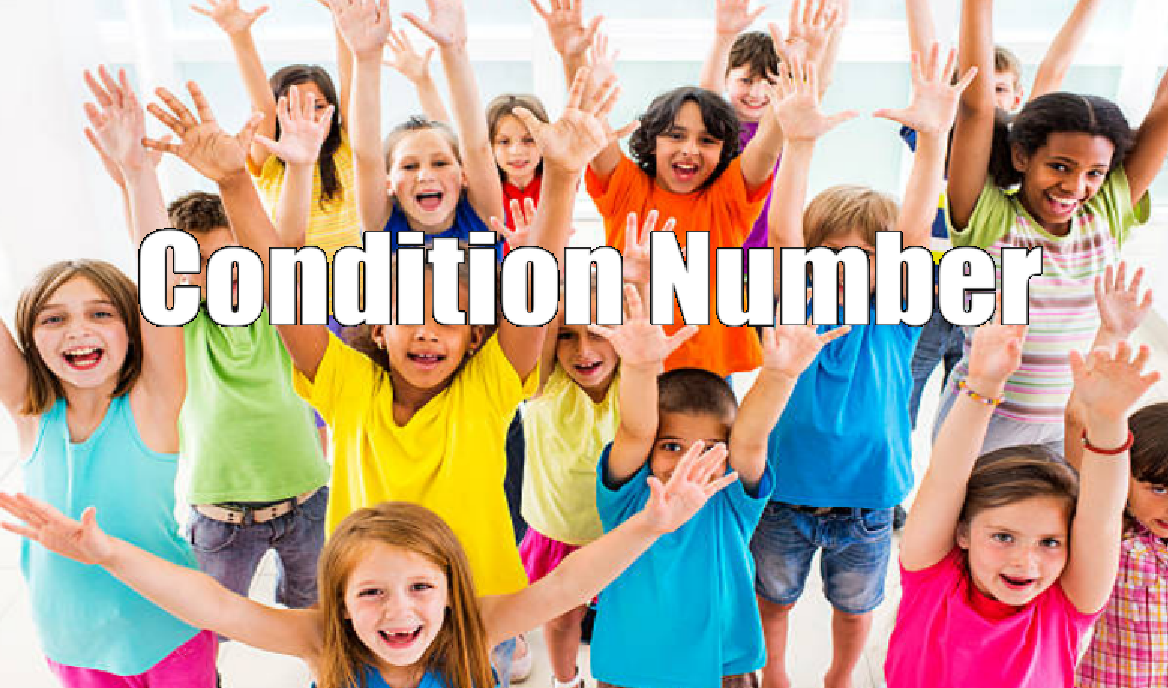

### Piccola digressione sul numero di condizionamento

In [ ]:
# Definisco una matrice A quasi-singolare (le due righe sono quasi identiche)
A = np.array([[1, 1], [1, 1.001]])

# Definisco il vettore dei termini noti con una piccola perturbazione
b = np.array([2, 2.001])

# Risolvo il sistema lineare Ax = b: piccole perturbazioni causano grandi errori
x = np.linalg.solve(A, b)
x

In [ ]:
def matrice_mal_condizionata(shape, cond=1e8, seed=10):
    """
    Genera una matrice con numero di condizionamento circa pari a cond.

    Parameters
    ----------
    - shape : tuple
        Dimensioni della matrice (n, m).

    - cond : float
        Numero di condizionamento desiderato (>= 1).

    - seed : int
        Seed per la riproducibilità.

    """
    # Estraggo le dimensioni della matrice
    n, m = shape

    # Verifico che le dimensioni siano positive
    if n == 0 or m == 0:
        raise ValueError("Le dimensioni devono essere positive.")
    # Verifico che il numero di condizionamento richiesto sia >= 1
    if cond < 1:
        raise ValueError("Il numero di condizionamento deve essere >= 1.")

    # Inizializzo il generatore di numeri casuali con il seed specificato
    rng = np.random.default_rng(seed)
    r = min(n, m)

    # Genero due matrici ortonormali U (n x r) e V (m x r) tramite decomposizione QR
    U, _ = np.linalg.qr(rng.standard_normal((n, r)))
    V, _ = np.linalg.qr(rng.standard_normal((m, r)))

    # Costruisco valori singolari decrescenti geometricamente da 1 a 1/cond
    s = np.geomspace(1.0, 1.0 / cond, r)

    # Ricostruisco la matrice come U * diag(s) * V^T
    X = U @ np.diag(s) @ V.T

    return X

# Genero una matrice mal condizionata con le stesse dimensioni del dataset
X_bad = matrice_mal_condizionata((points, d), cond=1e8, seed=10)

Numero di condizionamento prima della regolarizzazione:
$$
\boxed{
\kappa_2(X^TX)=
\frac{\lambda_{\max}(X^TX)}
{\lambda_{\min}(X^TX)}
}
$$

In [ ]:
# TODO

# Calcolo la matrice X^T X
XtX = X_bad.T @ X_bad


# Calcolo gli autovalori (che essendo X^T X simmetrica sono reali e >= 0)
eigvals = np.linalg.eigvalsh(XtX)

# Applico la formula kappa_2 = lambda_max / lambda_min
kappa_before = eigvals.max() / eigvals.min()
print(f"Numero di condizionamento di X^T X prima della regolarizzazione: {kappa_before:.4e}")


È dimostrabile (bastano un po' di derivate) che aggiungere il termine di regolarizzazione L2
$$
\mathcal{L}=\frac{1}{n}\|y-Xw\|_{2}^{2}+\alpha\|w\|_{2}^{2}
$$
è analiticamente equivalente a risolvere la regressione lineare aggiungendo una matrice identità nel calcolo di $X^TX$

$$
w=(X^{T}X + \alpha I)^{-1}X^{T}y
$$

Numero di condizionamento dopo la regolarizzazione:
$$
\boxed{
\kappa_2(X^TX + \alpha_{reg}I)=
\frac{\lambda_{\max}(X^TX+ \alpha_{reg}I)}
{\lambda_{\min}(X^TX+ \alpha_{reg}I)}
}
$$

In [ ]:
# TODO

# Scelgo un valore di alpha per la regolarizzazione
alpha_reg = 1.0

# Aggiungo alpha * I alla matrice X^T X
XtX_reg = XtX + alpha_reg * np.eye(XtX.shape[0])

# Calcolo gli autovalori della matrice regolarizzata
eigvals_reg = np.linalg.eigvalsh(XtX_reg)

# Calcolo il nuovo numero di condizionamento
kappa_after = eigvals_reg.max() / eigvals_reg.min()
print(f"Numero di condizionamento di X^T X + alpha*I (dopo la regolarizzazione): {kappa_after:.4e}")

Quando otteniamo una matrice mal condizionata? Quando c'è correlazione tra le feature!

In [ ]:
# TODO

# Genero due colonne di dati casuali (una feature "vera")
X_corr = np.random.normal(0, 1, (100, 2))

# Rendo la seconda colonna quasi identica alla prima, aggiungendo solo un piccolissimo rumore
X_corr[:, 1] = X_corr[:, 0] + 0.001 * np.random.normal(0, 1, 100)

# Calcolo X^T X e i suoi autovalori
XtX_corr = X_corr.T @ X_corr
eigvals_corr = np.linalg.eigvalsh(XtX_corr)

# Verifico quanto è alto il numero di condizionamento
kappa_corr = eigvals_corr.max() / eigvals_corr.min()
print(f"Numero di condizionamento con feature correlate: {kappa_corr:.4e}")


Loss dell'errore quadratico e suo gradiente per la **Regressione Ridge**:

$$
\mathcal{L}=\frac{1}{n}\|y-Xw\|_{2}^{2}+\lambda\|w\|_{2}^{2},\;\;\;\;\nabla_{w} \mathcal{L} = -\frac{2}{n}X^T(y-Xw)+2\lambda w
$$

La Regressione Ridge esegue una regolarizzazione $L2$, cioè minimizza la somma dei quadrati penalizzata in modo che vengano preferiti $w$ più piccoli: infatti più i $w$ sono vicini a $0$, minore è la funzione di loss.

In [ ]:
def RidgeSquareLoss(X, y, w, lam):
    """
    Parametri
    ----------
    - X : array di float di dimensione n x d
        Matrice contenente il dataset

    - y : array di float di dimensione n
        Vettore contenente il valore target di ogni punto dati

    - w : array di float di dimensione d
        Pesi della retta fittata

    - lam : float
        Peso del termine di penalizzazione L2
    """
    points = X.shape[0]
    # 1. Calcolo la loss MSE: (1/n) * ||y - Xw||_2^2
    # 2. Aggiungo il termine di penalizzazione L2: lam * ||w||_2^2
    # Uso LA.norm per calcolare la norma L2 di un vettore
    return (1 / points) * LA.norm(y - X @ w, 2)**2 + lam * LA.norm(w, 2)**2


def RidgeGradient(w, lam):
    # Gradiente del termine di penalizzazione L2 rispetto a w: 2 * lam * w
    return 2 * lam * w


def GDRidge(X, y, iters, gamma, d, lam):
    """
    Parametri
    ----------
    - X : array di float di dimensione n x d
        Matrice contenente il dataset

    - y : array di float di dimensione n
        Vettore contenente il valore target di ogni punto dati

    - iters : int
        Numero di iterazioni della GD

    - gamma : float
        Learning rate

    - d : int
        Dimensionalità di ogni punto dati nel dataset

    - lam : float
        Peso del termine di penalizzazione L2
    """
    #  Inizializzo le matrici per salvare pesi e loss
    W = np.zeros((d,iters))
    L = np.zeros(iters)
    points = X.shape[0]

    # Parto da w = 0 (invece che da valori casuali, per stabilità) -> w = np.random.normal(0,0.1,d)
    w = np.zeros(d)

    # A ogni iterazione faccio un passo di GD con il gradiente totale -> (MSE + regolarizzazione Ridge)
    for i in range(iters):
        W[:,i] = w
        w = w - gamma * (OLSGradient(X, y, w, points) + RidgeGradient(w, lam))
        L[i] = RidgeSquareLoss(X, y, w, lam)
    return W, L

In [ ]:
# Estraggo la dimensionalità delle feature
d = np.shape(X)[1]

# Fissо iperparametri: iterazioni, learning rate e forza della regolarizzazione
iters = 100
gamma = 0.001
lam = 0.01

# Eseguo la GD con regolarizzazione Ridge
wgdR, L = GDRidge(X, y, iters, gamma, d, lam)

# Estraggo i pesi finali
wpredRidge = wgdR[:,-1]

# Confronto i pesi appresi con quelli reali
print('Norma L2 della differenza tra pesi reali e pesi predetti: ', LA.norm(w-wpredRidge,2))
print(f"norma di w={np.linalg.norm(wpredRidge):.4f}")

In [ ]:
# Creo una figura con due pannelli affiancati per confrontare la loss su due scale
plt.figure(figsize=(12, 4))

# Pannello sinistro: loss in scala lineare
plt.subplot(1, 2, 1)
plt.plot(L)
plt.title('Loss - Scala lineare')
plt.xlabel('Iterazione')
plt.ylabel('Loss')
plt.grid(True)

# Pannello destro: stessa loss in scala logaritmica
plt.subplot(1, 2, 2)
plt.plot(L)
plt.yscale('log')
plt.title('Loss - Scala logaritmica')
plt.xlabel('Iterazione')

plt.ylabel('Loss (log)')
plt.grid(True)

# Sistemo automaticamente la spaziatura tra i due pannelli
plt.tight_layout()

## Regolarizzazione Lasso

Loss dell'errore quadratico e suo gradiente per la **regolarizzazione Lasso (Least Absolute Shrinkage and Selection Operator)**:

$$
\mathcal{L}=\frac{1}{n}\|y-Xw\|_{2}^{2}+\lambda\|w\|_{1},\;\;\;\;\nabla_{w} \mathcal{L} = -\frac{2}{n}X^T(y-Xw) + ?
$$

Questo tipo di regolarizzazione può portare a zero i coefficienti, cioè alcune feature dei punti potrebbero essere completamente trascurate: può quindi essere usata e considerata anche come strategia di selezione delle feature.

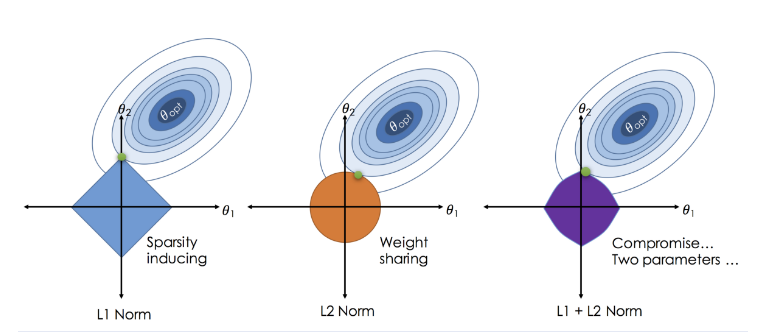

Dato che non possiamo calcolare il gradiente del termine di penalizzazione (in quanto non è differenziabile in $0$), useremo la **discesa del subgradiente**, ovvero un algoritmo per minimizzare una funzione convessa non differenziabile.

Definiamo il sub-differenziale della funzione valore assoluto come:

$$
\partial \|w\|_1 = \left\{\begin{matrix}
1 & w>0 \\  
-1 & w<0 \\
[-1, 1] & w=0
\end{matrix}\right.
$$

Quindi:

$$
\nabla_{w} \mathcal{L} = -\frac{2}{n}X^T(y-Xw)+\lambda \partial \|w\|_1
$$
$$

In [ ]:
def LassoSquareLoss(X, y, w, lam):
    """
    Parametri
    ----------
    - X : array di float di dimensione n x d
        Matrice contenente il dataset

    - y : array di float di dimensione n
        Vettore contenente il valore target di ogni punto dati

    - w : array di float di dimensione d
        Pesi della retta fittata

    - lam : float
        Peso del termine di penalizzazione L1

    """
    # TODO:
    points = X.shape[0]

    # Calcolo la loss MSE più la penalità L1 (somma assoluti dei pesi)
    loss = (1/ points) * LA.norm(y - X @ w, 2)**2 + lam *np.sum(np.abs(w))
    return loss

# TODO
def LassoGradient(w, lam):
    # Calcolo il subgradiente del termine di penalizzazione L1
    return  lam * np.sign(w)

In [ ]:
def GDLasso(X, y, iters, gamma, d, lam):
    """
     Parametri
    ----------
    - X : array di float di dimensione n x d
        Matrice contenente il dataset

    - y : array di float di dimensione n
        Vettore contenente il valore target di ogni punto dati

    - iters : int
        Numero di iterazioni della GD

    - gamma : float
        Learning rate

    - d : int
        Dimensionalità di ogni punto dati nel dataset

    - lam : float
        Peso del termine di penalizzazione L1
    """
    # Iniziallizzo le matrici per salvare pesi e loss
    W = np.zeros((d,iters))
    L = np.zeros(iters)

    # Parto da pesi piccoli ma casuali (il lasso non richiede w=0 iniziale)
    w = np.random.normal(0, 0.1, d)
    points = X.shape[0]

    #TODO
    # A ogni iterazione faccio un passo di GD con il subgradiente totale
    for i in range(iters):
        W[:,i] = w
        # Combino il gradiente MSE con il subgradiente del termine L1
        w = w - gamma * (OLSGradient(X, y, w, points) + LassoGradient(w, lam))
        L[i] = LassoSquareLoss(X, y, w, lam)
    return W, L

In [ ]:
# Estraggo la dimensionalità delle feature dal dataset
d = np.shape(X)[1]

# Fissо iperparametri: iterazioni, punti (non usato dentro GDLasso), learning rate, lambda
iters = 1000
points = 100
gamma = 0.001
lam = 0.01

# Eseguo la discesa del subgradiente con regolarizzazione Lasso
wgdL, L = GDLasso(X, y, iters, gamma, d, lam)

# Estraggo i pesi finali
wpredL = wgdL[:,-1]

# Confronto i pesi appresi con quelli reali
print('Norma L2 della differenza tra pesi reali e pesi predetti: ', LA.norm(w-wpredL,2))
print(f"norma di w={np.linalg.norm(wpredL):.4f}")

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(L)
plt.title('Loss - Linear scale')
plt.xlabel('Iter')
plt.ylabel('Loss')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(L)
plt.yscale('log')
plt.title('Loss - Log scale')
plt.xlabel('Iter')

plt.ylabel('Loss (log)')
plt.grid(True)

plt.tight_layout()

## Elastic Net

Metodo di regressione regolarizzata che combina le penalità $L1$ e $L2$ di Lasso e Ridge rispettivamente, per ottenere il meglio da entrambi.
La loss da minimizzare è definita come:

$$
L=\frac{1}{n}\|y-Xw\|_{2}^{2}+\lambda_1\|w\|_{1} + \lambda_2 \|w\|_2
$$

Quindi in questo problema abbiamo $2$ parametri da tarare.

Possiamo riscrivere il problema come segue, in modo da avere un solo parametro $\lambda$ da tarare (cioè come combinazione convessa delle penalità Ridge e Lasso):

$$
L=\frac{1}{n}\|y-Xw\|_{2}^{2}+(\lambda_r) \cdot \|w\|_{1} + (1 - \lambda_r) \cdot \|w\|_2
$$

dove $\lambda_r$, fornito in input, è l'_importanza_ data alla penalità $L1$ (è possibile anche l'opposto).

In [ ]:
# TODO

def ElasticNetSquareLoss(X, y, w, lam, l1_ratio):
    """
    Parametri
    ----------
    - X : array di float di dimensione n x d
        Matrice contenente il dataset

    - y : array di float di dimensione n
        Vettore contenente il valore target di ogni punto dati

    - w : array di float di dimensione d
        Pesi della retta fittata

    - lam : float
        Peso complessivo della regolarizzazione

    - l1_ratio : float
        Importanza relativa della penalità L1 rispetto alla L2 (in [0, 1])
    """
    points = X.shape[0]

    # Calcolo la loss MSE
    mse = (1 / points) * LA.norm(y - X @ w, 2)**2

    # Aggiungo la combinazione convessa di penalità L1 e L2, pesata da lam
    l1 = l1_ratio * np.sum(np.abs(w))
    l2 = (1 - l1_ratio) * LA.norm(w, 2)**2

    return mse + lam * (l1 + l2)


def ElasticNetGradient(w, lam, l1_ratio):

    # Subgradiente del termine di penalizzazione combinato
    l1_grad = l1_ratio * np.sign(w)
    l2_grad = (1 - l1_ratio) * 2 * w
    return lam * (l1_grad + l2_grad)


def GDElasticNet(X, y, iters, gamma, d, lam, l1_ratio):
    """
    Parametri
    ----------
    - X : array di float di dimensione n x d
        Matrice contenente il dataset

    - y : array di float di dimensione n
        Vettore contenente il valore target di ogni punto dati

    - iters : int
        Numero di iterazioni della GD

    - gamma : float
        Learning rate

    - d : int
        Dimensionalità di ogni punto dati nel dataset

    - lam : float
        Peso complessivo della regolarizzazione

    - l1_ratio : float
        Importanza relativa della penalità L1 rispetto alla L2 (in [0, 1])
    """
    W = np.zeros((d, iters))
    L = np.zeros(iters)
    w = np.random.normal(0, 0.1, d)
    points = X.shape[0]
    for i in range(iters):
        W[:, i] = w
        # Aggiorno i pesi combinando il gradiente MSE con quello del termine Elastic Net
        w = w - gamma * (OLSGradient(X, y, w, points) + ElasticNetGradient(w, lam, l1_ratio))
        L[i] = ElasticNetSquareLoss(X, y, w, lam, l1_ratio)
    return W, L

---

### Vediamo alcune performance

In [ ]:
# Importo strumenti di scikit-learn per dataset, split, modelli e metrica
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error

In [ ]:
# Creo un dataset di regressione con molte feature correlate e rumore
X, y = make_regression(
    n_samples=1000,
    n_features=15,
    n_informative=5,
    noise=25,
    effective_rank=14
)

# Divido in training set (70%) e test set (30%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

In [ ]:
# Fissо la forza della regolarizzazione
lam = 0.1

# Definisco quattro modelli: lineare puro, Ridge, Lasso ed Elastic Net
LinReg = LinearRegression()
RidgeReg = Ridge(alpha=lam)
LassoReg = Lasso(alpha=lam)
ElasticNetReg = ElasticNet(alpha=lam, l1_ratio=0.5)


In [ ]:
# TODO

# Alleno ciascun modello sul training set usando il metodo .fit()
LinReg.fit(X_train, y_train)
RidgeReg.fit(X_train, y_train)
LassoReg.fit(X_train, y_train)
ElasticNetReg.fit(X_train, y_train)


In [ ]:
# TODO: 

# Calcolo il Mean Squared Error di ciascun modello sul test set - (basta chiamare .predict() e passare le predizioni a mean_squared_error)
mse_lin = mean_squared_error(y_test, LinReg.predict(X_test))
mse_ridge = mean_squared_error(y_test, RidgeReg.predict(X_test))
mse_lasso = mean_squared_error(y_test, LassoReg.predict(X_test))
mse_elastic = mean_squared_error(y_test, ElasticNetReg.predict(X_test))

print(f"Mean Squared Error (Regressione Lineare): {mse_lin:.4f}")
print(f"Mean Squared Error (Regressione Ridge): {mse_ridge:.4f}")
print(f"Mean Squared Error (Regressione Lasso): {mse_lasso:.4f}")
print(f"Mean Squared Error (Regressione Elastic Net): {mse_elastic:.4f}")


### Ora vediamo gli effetti della regolarizzazione

In [ ]:
# Estraggo i coefficienti appresi da ciascun modello
coefs_lin = LinReg.coef_
coefs_ridge = RidgeReg.coef_
coefs_lasso = LassoReg.coef_
coefs_elastic = ElasticNetReg.coef_

# Confronto i coefficienti con un bar plot affiancato
plt.bar(np.arange(len(coefs_lin)) - 0.3, coefs_lin, width=0.2, label='Linear', alpha=0.7)
plt.bar(np.arange(len(coefs_ridge)) - 0.1, coefs_ridge, width=0.2, label='Ridge', alpha=0.7)
plt.bar(np.arange(len(coefs_lasso)) + 0.1, coefs_lasso, width=0.2, label='Lasso', alpha=0.7)
plt.bar(np.arange(len(coefs_elastic)) + 0.3, coefs_elastic, width=0.2, label='Elastic Net', alpha=0.7)
plt.xlabel('Indice della feature')
plt.ylabel('Valore del coefficiente')
plt.legend()
plt.title('Confronto dei coefficienti')

---

In [ ]:
from scipy.optimize import minimize

# Varianti

## Metodi di Regolarizzazione Strutturata

Sia $\mathcal{L}(\boldsymbol{\beta})$ la loss empirica. La regolarizzazione strutturata incorpora conoscenza a priori sulle relazioni tra le feature.

### 1. Group LASSO
$
\min_{\boldsymbol{\beta}}\;
\mathcal{L}(\boldsymbol{\beta})
+\lambda\sum_{g=1}^{G}w_g\|\boldsymbol{\beta}_g\|_2
$

Seleziona interi gruppi di feature congiuntamente, portando a zero tutti i coefficienti di un gruppo o mantenendo l'intero gruppo. Utile per variabili categoriche, famiglie di feature e multi-task learning.

Paper: [Yuan & Lin (2006)](https://doi.org/10.1111/j.1467-9868.2005.00532.x).

### 2. Sparse Group LASSO
$
\min_{\boldsymbol{\beta}}\;
\mathcal{L}(\boldsymbol{\beta})
+\lambda_1\|\boldsymbol{\beta}\|_1
+\lambda_2\sum_g w_g\|\boldsymbol{\beta}_g\|_2
$

Combina la selezione a livello di gruppo con la selezione delle singole feature all'interno di ciascun gruppo.

Paper: [Simon et al. (2013)](https://doi.org/10.1214/13-AOAS627).

### 3. Fused LASSO
$
\min_{\boldsymbol{\beta}}\;
\mathcal{L}(\boldsymbol{\beta})
+\lambda_1\|\boldsymbol{\beta}\|_1
+\lambda_2\sum_{j=2}^{p}|\beta_j-\beta_{j-1}|
$

Favorisce sia coefficienti sparsi sia coefficienti simili per feature adiacenti. Utile per variabili ordinate, serie temporali e dati genomici.

Paper: [Tibshirani et al. (2005)](https://doi.org/10.1111/j.1467-9868.2005.00490.x).


### Group lasso

---

# Ora giochiamo

In [ ]:
# Rigenero il dataset di regressione con feature correlate 
X, y = make_regression(
    n_samples=1000,
    n_features=15,
    n_informative=5,
    noise=25,
    effective_rank=14
)

# Divido di nuovo in train e test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

In [ ]:
class CustomRegressor:
    def __init__(self, reg_function, lam=0.01):
        # Salvo la forza della regolarizzazione e la funzione di penalità scelta
        self.lam = lam

        # Inizializzo i coefficienti a None (verranno stimati in fit)
        self.coef_ = None
        self.reg_function = reg_function

    def fit(self, X, y):
        n_samples, n_features = X.shape

        def objective(weights):
            # Loss empirica: MSE (media dei quadrati dei residui)
            residuals = y - X @ weights

            data_loss = np.sum(residuals**2) / (n_samples)
            # Aggiungo il termine di regolarizzazione pesato da lam
            return data_loss + self.lam * self.reg_function(weights)

        # Parto da pesi tutti nulli
        initial_weights = np.zeros(n_features)

        # Ottimizzo la funzione obiettivo con BFGS
        result = minimize(objective, initial_weights, method='BFGS')

        # Se l'ottimizzatore non converge, lo segnalo
        if not result.success:
                print("Attenzione:", result.message)
                
        # Salvo i coefficienti ottimali
        self.coef_ = result.x

    def predict(self, X):
        # Predizione lineare: X @ coef_
        return X @ self.coef_

In [ ]:
def my_reg(weights):
    # Esempio di funzione di regolarizzazione (somma dei pesi)
    return np.sum(weights)

# Istanzio il regressore custom con la mia funzione di penalità
my_regressor = CustomRegressor(lam=0.01, reg_function=my_reg)
my_regressor.fit(X_train, y_train)
y_pred = my_regressor.predict(X_test)

# Calcolo l'errore quadratico medio sul test set
mse_custom = mean_squared_error(y_test, y_pred)
mse_custom

---

# Domande in stile esame

- Perché Lasso effettua selezione delle variabili?
- Spiegare il concetto di pseudogradiente per la regolarizzazione Lasso

<span style="color:red">**Domanda 1: Perché Lasso effettua la selezione delle variabili?**</span>

La regolarizzazione Lasso aggiunge una penalità $L1$ alla loss MSE:

$$
\mathcal{L}(w) = \frac{1}{n}\|y - Xw\|_2^2 + \lambda\|w\|_1
$$

La selezione delle variabili è una conseguenza della **geometria della palla $L1$**. Riscrivendo il problema in forma vincolata:

$$
\min_w \|y - Xw\|_2^2 \quad \text{s.t.} \quad \|w\|_1 \le t
$$

la regione ammissibile è un **politopo con vertici sugli assi coordinati**. La soluzione ottima si trova nel punto in cui le curve di livello della MSE (ellissi) toccano il bordo del politopo: poiché i vertici e gli spigoli giacciono sugli assi, la tangenza cade **spesso su coordinate esattamente nulle**. Più $\lambda$ è grande, più il vincolo è stretto, più coefficienti diventano $0$: le feature corrispondenti sono così **ignorate** dal modello.

Ridge, al contrario, usa una palla $L2$ (sfera liscia, senza vertici): il punto di tangenza è in posizione generica e i coefficienti vengono **ridotti** ma mai azzerati. Da qui l'assenza di selezione delle variabili in Ridge.

**Interpretazione probabilistica**: Lasso corrisponde a uno stimatore MAP con prior di Laplace, che concentra massa intorno a $0$ e favorisce soluzioni sparse.

<span style="color:red">**Domanda 2: Spiegare il concetto di pseudogradiente per la regolarizzazione Lasso**</span>


Il termine di penalizzazione $\lambda\|w\|_1$ **non è differenziabile in $w = 0$**, perché $|w|$ ha un punto angoloso nell'origine. La discesa del gradiente classica non può quindi essere applicata direttamente.

Per gestire il problema si distinguono due concetti:

**Subgradiente** (concetto formale). Per una funzione convessa $f$, il subdifferenziale in $w$ è:
$$
\partial f(w) = \left\{ g \;\middle|\; f(z) \ge f(w) + g^\top(z - w), \;\forall z \right\}
$$
Per $|w|$ si ha $\partial|w| = \{\pm 1\}$ fuori da $0$ e $\partial|w| = [-1, +1]$ in $w = 0$.

**Pseudogradient** (scelta pratica). Per poter aggiornare numericamente i pesi serve un **singolo valore**, non un intervallo. Si sceglie quindi:
$$
\tilde{\nabla}\|w\|_1 = \mathrm{sign}(w) = \begin{cases} +1 & w>0 \\ -1 & w<0 \\ 0 & w=0 \end{cases}
$$
cioè il punto medio del subdifferenziale nell'origine.

L'aggiornamento risultante è:
$$
w \leftarrow w - \gamma\left(-\tfrac{2}{n}X^\top(y-Xw) + \lambda\,\mathrm{sign}(w)\right)
$$

**Osservazioni**:
- Vantaggio: riutilizza lo schema della GD classica ed è semplice da implementare.
- Limite: non garantisce la stessa convergenza del gradiente (non è un vero gradiente).
- Effetto pratico: favorisce comunque la **sparsità**, perché il termine $\mathrm{sign}(w)$ spinge i coefficienti piccoli verso $0$.
- Per garanzie teoriche servono algoritmi più raffinati (ISTA/FISTA, coordinate descent, LARS).